# 09 — Análisis de sentimientos de reseñas
## DataSmart Olist · Rama `feature/nlp`

**Pregunta de negocio:** ¿qué sentimiento expresan las reseñas escritas por los clientes y qué
temas o experiencias impulsan la insatisfacción?

**Etiqueta:** se construye desde la nota del cliente: 1–2 estrellas = Negativo, 3 = Neutro,
4–5 = Positivo. Es una etiqueta débil (mide satisfacción global, no sentimiento puro), pero es la
señal más cercana disponible para todo el dataset.

**Decisiones de evaluación:**
- **Macro-F1** como métrica principal, porque las clases están desbalanceadas.
- **PR-AUC / ROC-AUC de la clase negativa** para el uso operativo de priorización.
- **QWK y accuracy ±1** para evaluar la nota 1–5 como problema ordinal.
- **Deduplicación de textos** para evitar fuga entre entrenamiento y prueba.
- **Transformer externo zero-shot** entrenado en otro e-commerce (B2W), no en Olist, como referencia.

## 0. Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from src.models.sentiment import (
    LABEL_NAMES,
    build_features,
    clean_text,
    cross_validate_models,
    default_logistic,
    load_reviews,
    make_splits,
    model_candidates,
    stratified_sample,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

CLASS_COLORS = {"Negativo": "#C8553D", "Neutro": "#E0A458", "Positivo": "#0799B6"}
LABEL_ORDER = ["Negativo", "Neutro", "Positivo"]
print("Raíz:", ROOT)

Raíz: /home/im/Documentos/Proyectos/Olist-ecommerce-analytics


## 1. Carga, deduplicación y etiqueta

El módulo conserva una reseña por pedido, combina título y mensaje, exige al menos una letra y
elimina duplicados exactos del texto normalizado. Así se evita que frases plantilla como *"Bom"* o
*"Não recebi"* aparezcan en train y test e inflen las métricas.

In [2]:
reviews = load_reviews()
print(f"Reseñas únicas con texto: {len(reviews):,}")
print(f"Periodo: {reviews.review_creation_date.min().date()} a {reviews.review_creation_date.max().date()}")
display(reviews.head(5))

11:59:52 | INFO    | Cargando reseñas desde: /home/im/Documentos/Proyectos/Olist-ecommerce-analytics/data/raw/olist_order_reviews_dataset.csv


11:59:54 | INFO    | Reseñas con texto: 42246 | tras deduplicar: 35044 (7202 duplicados exactos)


Reseñas únicas con texto: 35,044
Periodo: 2016-10-02 a 2018-08-31


,order_id,review_id,review_score,label,label_name,text,text_clean,n_words,text_len,review_creation_date,review_answer_timestamp
0,809a282bbd5dbcabb6f2f724fca862ec,69ac6a27fde9855ebeaaecac0f78058b,1,0,Negativo,MEU PEDIDO NÃO FOI ENTREGUE E NÃO FOI DADA NENHUMA SATISTAÇÃO,meu pedido não foi entregue e não foi dada nenhuma satistação,11,61,2016-10-02 00:00:00,2016-10-26 12:31:00
1,bfbd0f9bdef84302105ad712db648a6c,6916ca4502d6d3bfd39818759d55d536,1,0,Negativo,nao recebi o produto e nem resposta da empresa,nao recebi o produto e nem resposta da empresa,9,46,2016-10-06 00:00:00,2016-10-07 18:32:28
2,e5215415bb6f76fe3b7cb68103a0d1c0,49f695dffa457eaba90d388a5c37e942,1,0,Negativo,"PRODUTO NÃO CHEGOU,E JÁ PASSOU O PRAZO DE ENTREGA","produto não chegou,e já passou o prazo de entrega",9,49,2016-10-09 00:00:00,2016-10-11 14:31:29
3,9aa3197e4887919fde0307fc23601d7a,b2d5d8db2a841d27a72e4c06c6212368,4,2,Positivo,Só chegou uma parte do pedido ate agora,só chegou uma parte do pedido ate agora,8,39,2016-10-15 00:00:00,2016-10-17 21:02:49
4,b8b9d7046c083150cb5360b83a8ebb51,53752edb26544dd41c1209f582c9c589,5,2,Positivo,O pedido foi entregue antes do prazo pr0metido,o pedido foi entregue antes do prazo pr0metido,8,46,2016-10-16 01:00:00,2016-10-16 15:45:11


,label,label_name,resenas,porcentaje
0,0,Negativo,10259,0.292746
1,1,Neutro,3199,0.091285
2,2,Positivo,21586,0.615968


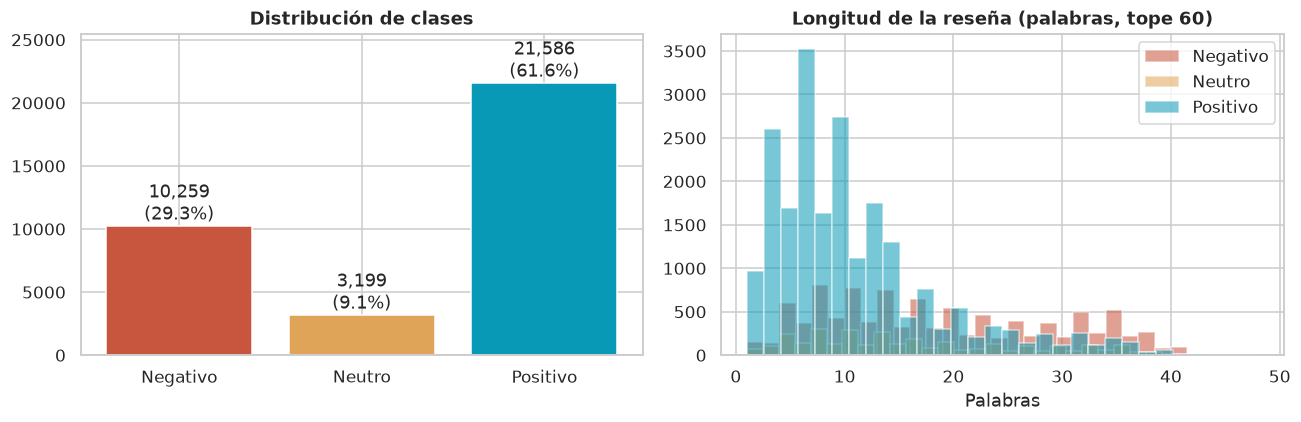

In [3]:
dist = (
    reviews.groupby(["label", "label_name"])
    .size()
    .reset_index(name="resenas")
    .sort_values("label")
)
dist["porcentaje"] = dist["resenas"] / len(reviews)
display(dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(
    dist.label_name,
    dist.resenas,
    color=[CLASS_COLORS[name] for name in dist.label_name],
    edgecolor="white",
)
for i, row in dist.iterrows():
    axes[0].text(i, row.resenas, f"{row.resenas:,}\n({row.porcentaje:.1%})", ha="center", va="bottom")
axes[0].set_title("Distribución de clases", fontweight="bold")
axes[0].set_ylim(0, dist.resenas.max() * 1.18)

for name in LABEL_ORDER:
    subset = reviews[reviews.label_name == name]
    axes[1].hist(subset.n_words.clip(upper=60), bins=30, alpha=0.55, label=name, color=CLASS_COLORS[name])
axes[1].set_title("Longitud de la reseña (palabras, tope 60)", fontweight="bold")
axes[1].set_xlabel("Palabras")
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Ejemplos por clase

El texto es corto, coloquial y ruidoso. Las reseñas negativas suelen hablar de entrega, defectos
o expectativas incumplidas; las neutras son ambiguas o descriptivas.

In [4]:
for name in LABEL_ORDER:
    print(f"\n--- {name} ---")
    for text in reviews[reviews.label_name == name].text.sample(4, random_state=42):
        print(" •", text[:320].replace("\n", " "))


--- Negativo ---
 Estou muito insatisfeita
 • Até o momento não foi entregue
 • Reclamação. Eu já paguei pelo produto e ele ainda não chegou
 • A espuma é tão fina que a porta passa por cima do protetor. Não serve pra nada. Perdi tempo, me aborreci e ainda tem a pior parte, devolve-lo no Correio na semana do Natal

--- Neutro ---
 • O que faltou foi ter enviado o manual em português pois está todo em inglês, por isso não posso dar 5 estrelas pois até para testar vai ser difícil!!
 Para quem gosta, o encosto mantém a coluna bem reta. Não tem opção de inclinação
 • O produto nunca apareceu em casa!
 • O produto veio estourado

--- Positivo ---
 • Avaliação. Comprei um produto pelo site e foi entregue no prazo e em perfeitas condições
 • Recebi dentro do prazo produto excelente
 • Produto chegou antes do previsto e possui ótima qualidade. Recomendo
 • Excelente ... prazo de entrega excelente !


## 3. Preprocesamiento y representación

- Normalización Unicode, minúsculas, eliminación de HTML/URLs/correos.
- Se conservan acentos, puntuación y negaciones (`não`, `nunca`, `sem`).
- TF-IDF de palabras (1–2 n-gramas) + TF-IDF de caracteres (3–5 n-gramas).

In [5]:
ejemplos = [
    "  <b>ÓTIMO</b> produto! https://exemplo.com  ",
    "NÃO recebi o pedido, uma pena!!!",
    "Produto ok, mas a embalagem veio amassada.",
]
for texto in ejemplos:
    print(repr(texto), "→", repr(clean_text(texto)))

features = build_features()
matriz = features.fit_transform(reviews.text_clean.head(2000))
print(f"\nMatriz TF-IDF de ejemplo: {matriz.shape[0]:,} filas × {matriz.shape[1]:,} columnas")

'  <b>ÓTIMO</b> produto! https://exemplo.com  ' → 'ótimo produto!'
'NÃO recebi o pedido, uma pena!!!' → 'não recebi o pedido, uma pena!!!'
'Produto ok, mas a embalagem veio amassada.' → 'produto ok, mas a embalagem veio amassada.'



Matriz TF-IDF de ejemplo: 2,000 filas × 12,023 columnas


## 4. Comparación rápida de algoritmos (submuestra)

Esta sección entrena sobre una submuestra balanceada para que el notebook sea rápido. La
comparación definitiva se ejecuta en el pipeline productivo con los 28,035 registros de
entrenamiento y 5 folds. La selección se hace por macro-F1.

In [6]:
sample = stratified_sample(reviews, n_per_class=600, random_state=42)
train_sample, test_sample = make_splits(sample, test_size=0.25, random_state=42)
print(f"Submuestra: train={len(train_sample):,} | test={len(test_sample):,}")

models = model_candidates()
models["Regresión Logística"] = default_logistic()
cv = cross_validate_models(train_sample.text_clean, train_sample.label, models, n_splits=3)
display(
    cv[
        [
            "modelo",
            "macro_f1_cv",
            "weighted_f1_cv",
            "accuracy_cv",
            "balanced_accuracy_cv",
            "cohen_kappa_cv",
            "tiempo_cv_seg",
        ]
    ].round(4)
)

Submuestra: train=1,350 | test=450


,modelo,macro_f1_cv,weighted_f1_cv,accuracy_cv,balanced_accuracy_cv,cohen_kappa_cv,tiempo_cv_seg
0,Regresión Logística,0.6834,0.6834,0.6837,0.6837,0.7033,0.8
1,SVM lineal calibrado,0.6659,0.6659,0.6667,0.6667,0.6931,0.8
2,Naive Bayes (ComplementNB),0.6427,0.6427,0.6556,0.6556,0.6683,0.6
3,Baseline (clase mayoritaria),0.1667,0.1667,0.3333,0.3333,0.0000,0.7


> La submuestra está balanceada, así que el accuracy y el macro-F1 son más altos que en la
> población real. Sirve para comparar algoritmos, no para reportar el desempeño final.

## 5. Resultados del pipeline productivo

El pipeline completo se ejecuta con:

```bash
python -m src.models.sentiment
```

Genera los artefactos de `artifacts/nlp/` y valida el manifest contra
`docs/module_contract.schema.json`.

In [7]:
ART = ROOT / "artifacts" / "nlp"
manifest = json.loads((ART / "manifest.json").read_text(encoding="utf-8"))
comparison = pd.read_csv(ART / "comparacion_modelos.csv")
per_class = pd.read_csv(ART / "metricas_por_clase.csv")
chart = json.loads((ART / "chart_data.json").read_text(encoding="utf-8"))

print("Modelo ganador:", manifest["winner"])
display(pd.DataFrame([manifest["metrics"]]).T.rename(columns={0: "valor"}))
display(comparison.round(4))
display(per_class.round(4))

Modelo ganador: Regresión Logística + TF-IDF palabra/carácter


,valor
macro_f1,0.6769
weighted_f1,0.8349
accuracy,0.8368
balanced_accuracy,0.6815
cohen_kappa,0.8309
negative_pr_auc,0.8786
negative_roc_auc,0.9542
negative_f1,0.8363
negative_precision,0.7765
negative_recall,0.9059


,modelo,tipo,macro_f1_cv,macro_f1_test,weighted_f1_test,accuracy_test,balanced_accuracy_test,cohen_kappa_test,negative_pr_auc_test,negative_roc_auc_test,macro_f1_balanceado,n_test,n_balanceado,tiempo_cv_seg
0,Regresión Logística,clásico,0.6770,0.6769,0.8349,0.8368,0.6815,0.8309,0.8786,0.9542,0.6476,7009,1500,30.00
1,SVM lineal calibrado,clásico,0.6061,0.6157,0.8214,0.8528,0.6340,0.8193,0.8812,0.9555,0.5344,7009,1500,29.80
2,Naive Bayes (ComplementNB),clásico,0.6080,0.6126,0.8046,0.8259,0.6346,0.7736,0.8435,0.9437,0.5548,7009,1500,17.00
3,Baseline (clase mayoritaria),clásico,0.2541,0.2541,0.4695,0.6159,0.3333,0.0000,0.2928,0.5000,0.1667,7009,1500,17.00
4,Transformer BERTimbau (referencia zero-shot),transformer externo,NaN,NaN,0.6486,0.6873,0.6873,0.7433,NaN,NaN,0.6486,1500,1500,15.53


,clase,precision,recall,f1,soporte
0,Negativo,0.7922,0.8787,0.8332,2052.0
1,Neutro,0.2965,0.2641,0.2793,640.0
2,Positivo,0.9351,0.9018,0.9182,4317.0


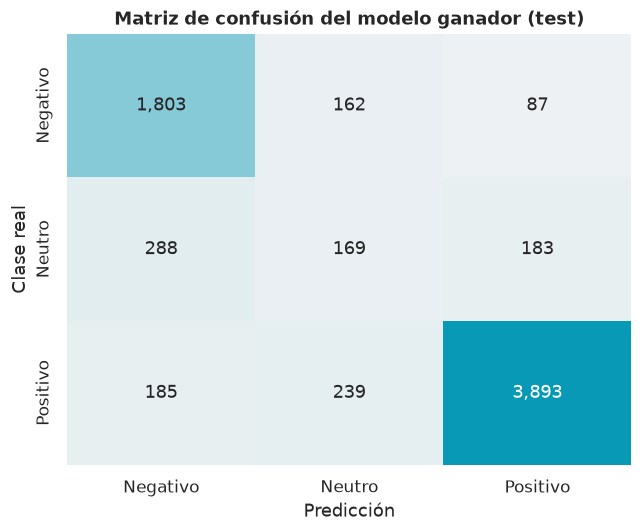

Interpretación: la clase neutra es la más confundida; el negativo se detecta con alto recall.


In [8]:
cm = np.array(chart["matriz_confusion"])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap=sns.light_palette("#0799B6", as_cmap=True),
    xticklabels=LABEL_ORDER,
    yticklabels=LABEL_ORDER,
    cbar=False,
    ax=ax,
)
ax.set_xlabel("Predicción")
ax.set_ylabel("Clase real")
ax.set_title("Matriz de confusión del modelo ganador (test)", fontweight="bold")
plt.tight_layout()
plt.show()

print("Interpretación: la clase neutra es la más confundida; el negativo se detecta con alto recall.")

## 6. Evaluación ordinal de la nota (1–5)

La nota original es ordinal. Un modelo auxiliar de 5 clases permite medir qué tan cerca queda la
nota reconstruida desde el texto. **QWK** castiga más los errores lejanos; **±1** mide si la
predicción queda a lo sumo a una estrella de la real.

QWK: 0.841 | Nota exacta: 67.4% | ±1 estrella: 88.8% | PR-AUC negativa: 0.878


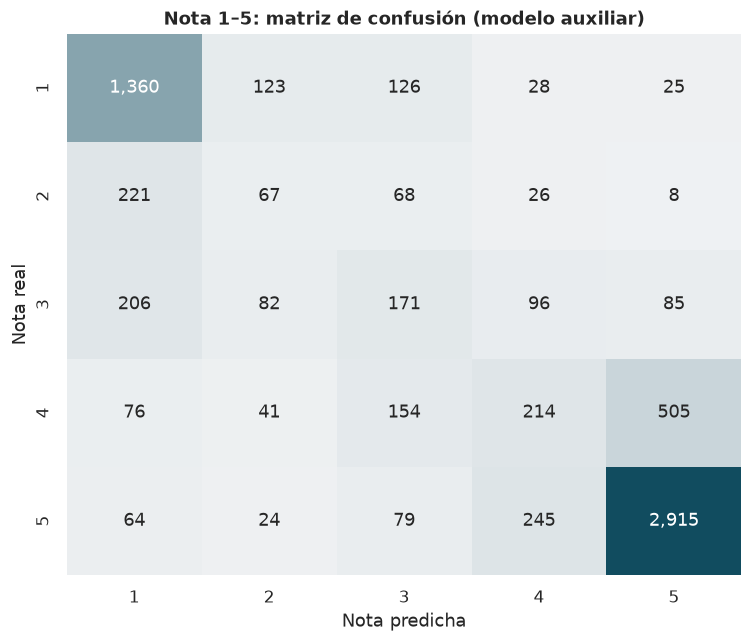

In [9]:
ordinal = chart["ordinal_5_estrellas"]
print(
    f"QWK: {ordinal['quadratic_weighted_kappa']:.3f} | "
    f"Nota exacta: {ordinal['exact_accuracy']:.1%} | "
    f"±1 estrella: {ordinal['off_by_one_accuracy']:.1%} | "
    f"PR-AUC negativa: {ordinal['negative_pr_auc']:.3f}"
)
cm5 = np.array(ordinal["confusion_matrix"])
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm5,
    annot=True,
    fmt=",d",
    cmap=sns.light_palette("#114C5F", as_cmap=True),
    xticklabels=ordinal["classes"],
    yticklabels=ordinal["classes"],
    cbar=False,
    ax=ax,
)
ax.set_xlabel("Nota predicha")
ax.set_ylabel("Nota real")
ax.set_title("Nota 1–5: matriz de confusión (modelo auxiliar)", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Interpretabilidad: términos con mayor peso

La regresión logística permite leer los pesos por clase sobre el vocabulario de palabras. No son
reglas causales, sino asociaciones aprendidas del texto.

In [10]:
terms = pd.read_csv(ART / "terminos_por_clase.csv")
for name in LABEL_ORDER:
    display(
        terms[(terms.clase == name) & (terms.grupo == "asociados")]
        .head(12)
        .reset_index(drop=True)
    )

,clase,grupo,termino,peso
0,Negativo,asociados,nao,5.576914
1,Negativo,asociados,nao recomendo,4.290002
2,Negativo,asociados,comprei,2.479234
3,Negativo,asociados,nao gostei,2.030278
4,Negativo,asociados,pessima,1.784570
5,Negativo,asociados,nem,1.757419
6,Negativo,asociados,produto nao,1.722215
7,Negativo,asociados,pessimo,1.635329
8,Negativo,asociados,nao chegou,1.525010
9,Negativo,asociados,nao recebi,1.508683


,clase,grupo,termino,peso
0,Neutro,asociados,porem,2.815654
1,Neutro,asociados,estou satisfeita,1.514701
2,Neutro,asociados,da compra,1.498528
3,Neutro,asociados,esperava mais,1.491743
4,Neutro,asociados,entrega muito,1.415086
5,Neutro,asociados,prazo material,1.414255
6,Neutro,asociados,prazo entrega,1.359353
7,Neutro,asociados,faltou,1.356266
8,Neutro,asociados,me atendeu,1.334216
9,Neutro,asociados,otimo muito,1.322057


,clase,grupo,termino,peso
0,Positivo,asociados,otimo,2.211138
1,Positivo,asociados,antes do,1.809520
2,Positivo,asociados,antes,1.759520
3,Positivo,asociados,amei,1.673462
4,Positivo,asociados,muito bom,1.622726
5,Positivo,asociados,parabens,1.619570
6,Positivo,asociados,excelente,1.578571
7,Positivo,asociados,otima,1.545745
8,Positivo,asociados,lindo,1.539139
9,Positivo,asociados,no prazo,1.481115


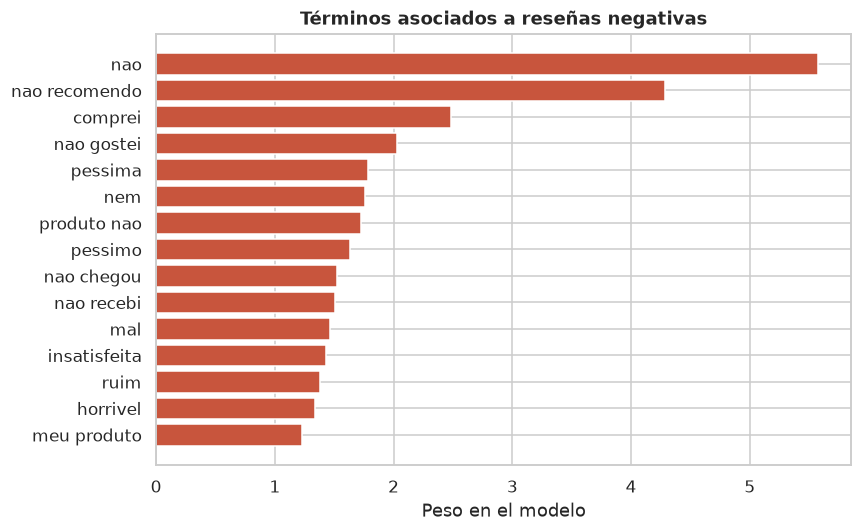

In [11]:
negative_terms = terms[(terms.clase == "Negativo") & (terms.grupo == "asociados")].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(negative_terms.termino, negative_terms.peso, color=CLASS_COLORS["Negativo"])
ax.set_title("Términos asociados a reseñas negativas", fontweight="bold")
ax.set_xlabel("Peso en el modelo")
plt.tight_layout()
plt.show()

## 8. Benchmark con transformer externo (zero-shot)

Se evaluó un BERTimbau fine-tuneado en reseñas de **B2W**, otro e-commerce brasileño, sobre la
misma muestra balanceada de test (500 por clase). No se entrenó con Olist ni se despliega en la
API: es una referencia externa honesta.

In [12]:
transformer = json.loads((ART / "transformer_benchmark.json").read_text(encoding="utf-8"))
print("Modelo:", transformer["model_id"])
print("Dispositivo:", transformer["device"], "| runtime:", transformer["runtime_sec"], "s")
print("Muestra:", transformer["sample"])
display(pd.DataFrame([transformer["metrics"]["per_class"]]).T.rename(columns={0: "BERTimbau B2W"}).round(4))

classic_balanced = comparison.loc[comparison.tipo == "clásico", "macro_f1_balanceado"].max()
print(f"\nMacro-F1 mejor clásico (muestra balanceada): {classic_balanced:.4f}")
print(f"Macro-F1 transformer (muestra balanceada): {transformer['metrics']['macro_f1']:.4f}")
print("→ Empate técnico; se despliega el clásico por latencia, costo e interpretabilidad.")

Modelo: Eduardo211000/bertimbau-sentimento-b2w
Dispositivo: cuda | runtime: 15.53 s
Muestra: {'n': 1500, 'per_class': 500, 'strategy': 'Test estratificado balanceado (misma partición que el modelo clásico)', 'note': 'Muestra balanceada para comparar macro-F1 entre clases. No representa la prevalencia natural del test.'}


,BERTimbau B2W
Negativo,"{'precision': 0.627906976744186, 'recall': 0.918, 'f1': 0.7457351746547523, 'support': 500}"
Neutro,"{'precision': 0.6855670103092784, 'recall': 0.266, 'f1': 0.38328530259365995, 'support': 500}"
Positivo,"{'precision': 0.7634782608695653, 'recall': 0.878, 'f1': 0.8167441860465117, 'support': 500}"



Macro-F1 mejor clásico (muestra balanceada): 0.6476
Macro-F1 transformer (muestra balanceada): 0.6486
→ Empate técnico; se despliega el clásico por latencia, costo e interpretabilidad.


## 9. Cruces de negocio

El sentimiento predicho se cruza con el tablón de pedidos (`data/processed/master_pedidos.csv`)
para identificar dónde se concentra la insatisfacción.

In [13]:
insights = chart["insights_negocio"]
display(pd.DataFrame(insights["por_estado_entrega"]).round(4))
display(pd.DataFrame(insights["por_categoria"]).head(10).round(4))

,estado_entrega,resenas,tasa_negativa,tasa_positiva
0,Entrega a tiempo,5857,0.2356,0.6778
1,Entrega tardía,800,0.7275,0.2100
2,Sin entrega,352,0.8920,0.0710


,categoria_principal,resenas,tasa_negativa,tasa_positiva
0,bed_bath_table,685,0.3489,0.5474
1,health_beauty,572,0.2885,0.6538
2,sports_leisure,495,0.3354,0.6061
3,computers_accessories,474,0.3376,0.5675
4,watches_gifts,466,0.2897,0.6202
5,furniture_decor,432,0.3565,0.5463
6,housewares,398,0.2990,0.6131
7,telephony,325,0.3415,0.5323
8,auto,275,0.3236,0.6145
9,garden_tools,273,0.3077,0.6190


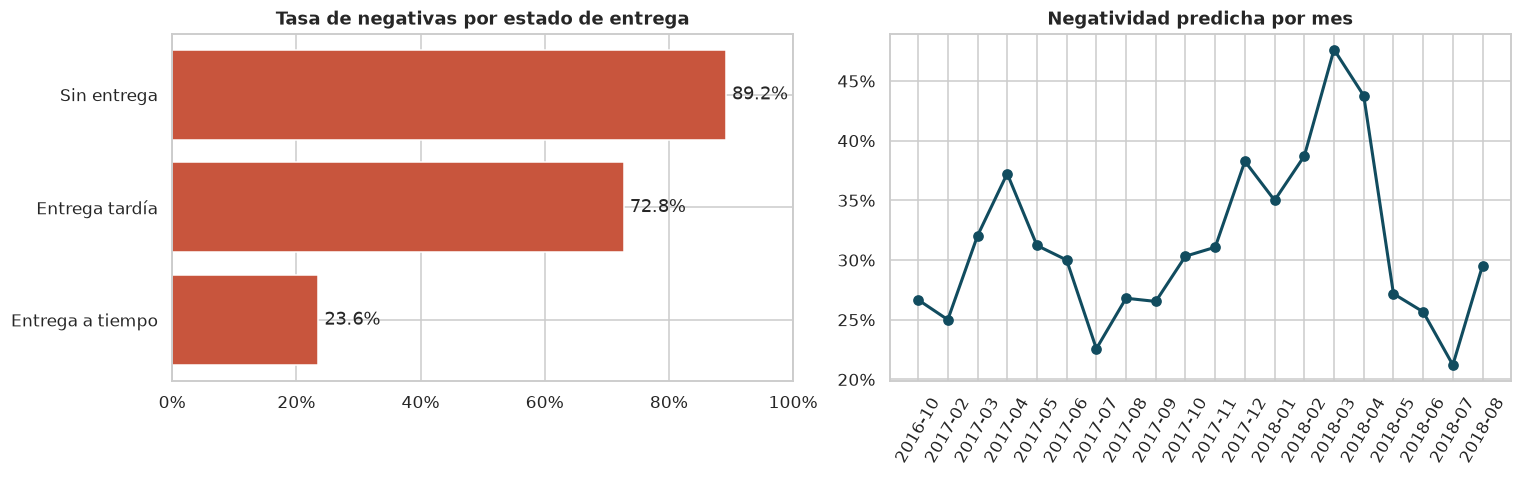

In [14]:
delivery = pd.DataFrame(insights["por_estado_entrega"]).sort_values("tasa_negativa")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].barh(delivery.estado_entrega, delivery.tasa_negativa, color="#C8553D")
for i, value in enumerate(delivery.tasa_negativa):
    axes[0].text(value, i, f" {value:.1%}", va="center")
axes[0].set_title("Tasa de negativas por estado de entrega", fontweight="bold")
axes[0].set_xlim(0, 1)
axes[0].xaxis.set_major_formatter(lambda value, _: f"{value:.0%}")

monthly = pd.DataFrame(insights["por_mes"]).sort_values("mes")
axes[1].plot(monthly.mes, monthly.tasa_negativa, marker="o", color="#114C5F", linewidth=2)
axes[1].set_title("Negatividad predicha por mes", fontweight="bold")
axes[1].tick_params(axis="x", rotation=60)
axes[1].yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
plt.tight_layout()
plt.show()

## 10. Conclusiones

1. **El modelo clásico es competitivo y desplegable.** La regresión logística con TF-IDF
   palabra+carácter obtiene **macro-F1 0.677** y **PR-AUC negativa 0.879** en test. Detecta el
   **90.6%** de las negativas con una precisión del **77.6%** usando el umbral operativo 0.374.
2. **La logística es la palanca principal.** Las reseñas de pedidos con entrega tardía tienen
   **72.8%** de negativas predichas, frente a **23.6%** de los entregados a tiempo y **89.2%**
   cuando no hay entrega registrada.
3. **La clase neutra es el límite.** El F1 de neutro es **0.279**: las reseñas de 3 estrellas son
   ambivalentes. Para decisiones operativas conviene usar la probabilidad de negativa, no solo
   la clase argmax.
4. **La nota es ordinal y el texto la reconstruye parcialmente.** El modelo auxiliar de 5 clases
   logra **QWK 0.841** y **88.8%** de acierto ±1 estrella, aunque la nota exacta se acierta en
   **67.4%**.
5. **El transformer zero-shot no supera claramente al clásico.** BERTimbau B2W obtiene
   **macro-F1 0.649** en la muestra balanceada, prácticamente el mismo resultado que el clásico
   (**0.648**). Fine-tunear BERTimbau con Olist en GPU es la mejora pendiente.
6. **La etiqueta tiene ruido.** Hay reseñas con texto positivo y nota negativa (y viceversa);
   son candidatas a revisión manual, no necesariamente fallos del modelo.

### Limitaciones

- La nota de 1–5 es una etiqueta débil; 3 estrellas es especialmente ambiguo.
- Solo ~41% de las reseñas tienen comentario; hay sesgo de selección.
- Portugués coloquial, ironía, sarcasmo, emojis y errores de tipeo.
- Se eliminaron duplicados exactos, pero pueden quedar near-duplicates.
- La partición train/test es aleatoria y estratificada, no temporal; mide generalización a reseñas similares, no deriva futura.
- Las tasas por categoría se calculan sobre el test y algunas categorías tienen menos de 200 reseñas; son señales exploratorias.
- El transformer es zero-shot y de otro dominio; no se fine-tuneó en Olist.
- Deriva temporal 2016–2018; se requiere monitoreo y reentrenamiento.
- Asociación no causal: retraso y negatividad están correlacionados.

## 11. Reproducción

```bash
pip install -r requirements.txt
python -m src.models.sentiment                 # pipeline principal
python -m pytest tests/test_sentiment.py -q    # pruebas
```

Benchmark opcional del transformer:

```bash
pip install -r requirements-nlp.txt
python scripts/benchmark_transformer.py --sample-per-class 500
```